In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

listings = pd.read_csv('../02_Data/processed/listings_clean.csv', low_memory=False)

In [2]:
nb_stats = listings.groupby('neighbourhood').agg(
    listings=('id', 'count'),
    median_price=('price', 'median'),
    q1_price=('price', lambda s: s.quantile(0.25)),
    q3_price=('price', lambda s: s.quantile(0.75)),
    pct_entire_home=('room_type', lambda s: (s == 'Entire home/apt').mean() * 100),
    pct_private_room=('room_type', lambda s: (s == 'Private room').mean() * 100),
    valid_prices=('price', 'count')
).reset_index()

nb_stats['share_of_supply_%'] = (nb_stats['listings'] / nb_stats['listings'].sum() * 100).round(1)
nb_stats = nb_stats[nb_stats['listings'] >= 30]

# Top 10 by Supply
print("Top 10 Neighbourhoods by Supply")
display(nb_stats.sort_values('listings', ascending=False).head(10))

# Top 10 by Median Price
print("\n Top 10 Neighbourhoods by Median Price")
display(nb_stats.sort_values('median_price', ascending=False).head(10))

Top 10 Neighbourhoods by Supply


,neighbourhood,listings,median_price,q1_price,q3_price,pct_entire_home,pct_private_room,valid_prices,share_of_supply_%
47,la Dreta de l'Eixample,2145,234.000,141.9350,379.0000,71.095571,26.573427,1943,14.0
41,el Raval,1031,99.285,64.4075,180.4075,59.359845,39.767216,874,6.7
16,"Sant Pere, Santa Caterina i la Ribera",925,141.000,78.1450,251.0000,68.540541,29.729730,799,6.0
65,la Vila de Gràcia,924,198.400,98.4500,278.5000,75.216450,22.943723,823,6.0
56,la Sagrada Família,910,248.500,135.6600,333.0000,77.362637,21.758242,805,6.0
26,el Barri Gòtic,881,133.995,79.9100,240.9650,62.769580,37.116913,758,5.8
43,l'Antiga Esquerra de l'Eixample,850,200.000,110.8300,322.0000,74.588235,23.647059,745,5.6
11,Sant Antoni,846,222.625,125.7625,324.7475,76.595745,23.286052,748,5.5
54,la Nova Esquerra de l'Eixample,660,214.915,104.5175,320.2500,73.030303,25.757576,580,4.3
38,el Poble Sec,650,206.000,123.2450,263.2750,80.461538,18.000000,587,4.3



 Top 10 Neighbourhoods by Median Price


,neighbourhood,listings,median_price,q1_price,q3_price,pct_entire_home,pct_private_room,valid_prices,share_of_supply_%
2,Diagonal Mar i el Front Marítim del Poblenou,119,325.000,190.4525,433.2500,87.394958,12.605042,104,0.8
64,la Vila Olímpica del Poblenou,135,272.460,115.6150,384.6250,88.148148,7.407407,123,0.9
56,la Sagrada Família,910,248.500,135.6600,333.0000,77.362637,21.758242,805,6.0
35,el Fort Pienc,424,247.500,107.6700,346.0000,74.056604,25.000000,373,2.8
47,la Dreta de l'Eixample,2145,234.000,141.9350,379.0000,71.095571,26.573427,1943,14.0
37,el Parc i la Llacuna del Poblenou,161,223.000,146.6000,298.6100,76.397516,18.012422,137,1.1
11,Sant Antoni,846,222.625,125.7625,324.7475,76.595745,23.286052,748,5.5
39,el Poblenou,437,219.000,118.6850,265.0000,85.354691,14.645309,379,2.9
54,la Nova Esquerra de l'Eixample,660,214.915,104.5175,320.2500,73.030303,25.757576,580,4.3
38,el Poble Sec,650,206.000,123.2450,263.2750,80.461538,18.000000,587,4.3


In [3]:
top_nbs = nb_stats.nlargest(10, 'listings')['neighbourhood'].tolist()
top_data = listings[listings['neighbourhood'].isin(top_nbs)]

# Crosstab: Median Price by Neighbourhood & Room Type
price_matrix = top_data.pivot_table(
    values='price', index='neighbourhood', columns='room_type', aggfunc='median'
).round(0)

# Crosstab: Counts by Neighbourhood & Room Type (to check sample sizes)
count_matrix = pd.crosstab(top_data['neighbourhood'], top_data['room_type'])

print("Median Price by Neighbourhood & Room Type")
display(price_matrix)
print("\nListing Counts (Sample Sizes)")
display(count_matrix)

--- Median Price by Neighbourhood & Room Type ---


room_type,Entire home/apt,Hotel room,Private room,Shared room
neighbourhood,,,,
Sant Antoni,250.0,NaN,117.0,NaN
"Sant Pere, Santa Caterina i la Ribera",159.0,368.0,98.0,NaN
el Barri Gòtic,160.0,NaN,91.0,64.0
el Poble Sec,225.0,162.0,80.0,40.0
el Raval,108.0,NaN,90.0,71.0
l'Antiga Esquerra de l'Eixample,244.0,197.0,78.0,47.0
la Dreta de l'Eixample,293.0,176.0,114.0,46.0
la Nova Esquerra de l'Eixample,251.0,156.0,59.0,36.0
la Sagrada Família,275.0,187.0,38.0,NaN



--- Listing Counts (Sample Sizes) ---


room_type,Entire home/apt,Hotel room,Private room,Shared room
neighbourhood,,,,
Sant Antoni,648,0,197,1
"Sant Pere, Santa Caterina i la Ribera",634,16,275,0
el Barri Gòtic,553,0,327,1
el Poble Sec,523,1,117,9
el Raval,612,4,410,5
l'Antiga Esquerra de l'Eixample,634,2,201,13
la Dreta de l'Eixample,1525,15,570,35
la Nova Esquerra de l'Eixample,482,4,170,4
la Sagrada Família,704,6,198,2


Thresholds -> Supply: 119 listings, Price: €158
market_position
High Supply / High Price    18
Low Supply / Low Price      17
Low Supply / High Price      6
High Supply / Low Price      6
Name: count, dtype: int64


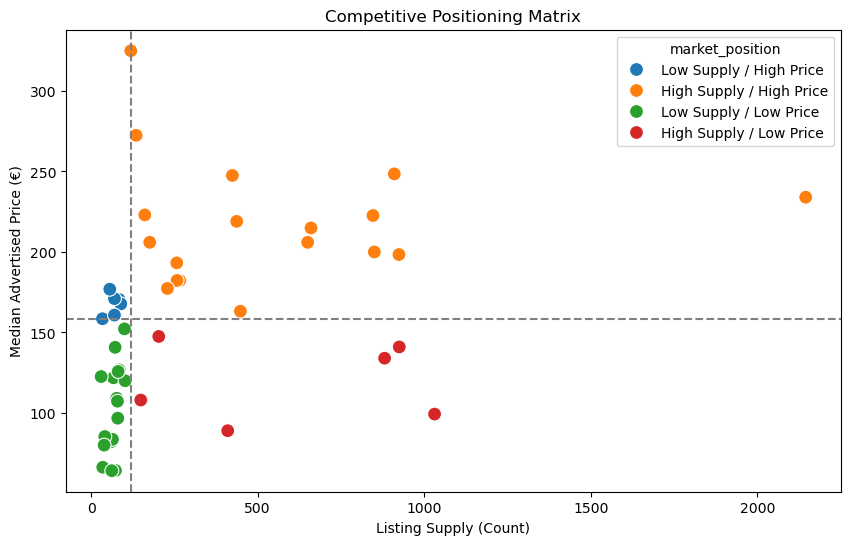

In [5]:
median_supply = nb_stats['listings'].median()
median_price = nb_stats['median_price'].median()

def classify_market(row):
    high_supply = row['listings'] >= median_supply
    high_price = row['median_price'] >= median_price
    
    if high_supply and high_price: return "High Supply / High Price"
    elif high_supply and not high_price: return "High Supply / Low Price"
    elif not high_supply and high_price: return "Low Supply / High Price"
    else: return "Low Supply / Low Price"

nb_stats['market_position'] = nb_stats.apply(classify_market, axis=1)

print(f"Thresholds -> Supply: {median_supply:.0f} listings, Price: €{median_price:.0f}")
print(nb_stats['market_position'].value_counts())

# Scatter Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=nb_stats, x='listings', y='median_price', hue='market_position', s=100)
plt.axvline(median_supply, color='gray', ls='--')
plt.axhline(median_price, color='gray', ls='--')
plt.title('Competitive Positioning Matrix')
plt.xlabel('Listing Supply (Count)')
plt.ylabel('Median Advertised Price (€)')
plt.show()